# КТ 1 — EDA сырого корпуса

Корпус собран скриптом `scripts/build_corpus.py` (описание источников и решений — в `README.md`).
Здесь он анализируется **до какой-либо чистки**: HTML-разметка, эмодзи, ссылки и дубликаты на месте.

Вопросы, на которые отвечает EDA:
1. Какой типичный размер документа и насколько он варьируется?
2. Что составляет основной шум в данных?
3. Какие тематические кластеры есть в корпусе?
4. Какие проблемы это создаст для чанкинга и ретрива?

In [1]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasketch import MinHash, MinHashLSH

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)

corpus_bytes = (DATA / "corpus.jsonl").read_bytes()
CORPUS_SHA = hashlib.sha256(corpus_bytes).hexdigest()
df = pd.DataFrame([json.loads(l) for l in corpus_bytes.decode("utf-8").splitlines()])
assert df["doc_id"].is_unique
df["date"] = pd.to_datetime(df["date"])
TAG_RE = re.compile(r"<[^>]+>")
df["visible"] = df["text"].map(lambda t: re.sub(r"\s+", " ", TAG_RE.sub(" ", t)).strip())
print(len(df), "документов, sha256 корпуса:", CORPUS_SHA[:16])


def cache_path(name: str, ext: str, **params) -> Path:
    """Путь кэша, привязанный к содержимому корпуса и параметрам расчёта.

    Пересборка корпуса или смена модели/параметров дают новый ключ — старый кэш
    просто не находится, и результат пересчитывается.
    """
    key = hashlib.sha256(json.dumps({"corpus": CORPUS_SHA, **params}, sort_keys=True).encode()).hexdigest()[:16]
    return CACHE / f"{name}-{key}.{ext}"

20990 документов, sha256 корпуса: dd9e4099df41a267


## 1. Состав корпуса

In [2]:
by_src = df.groupby("source").agg(docs=("doc_id", "size"), first=("date", "min"), last=("date", "max"))
by_src["share_%"] = (by_src["docs"] / len(df) * 100).round(1)
by_src

,docs,first,last,share_%
source,,,,
dota2ru_article,36,2023-08-09,2026-09-15,0.2
dota2ru_comment,2692,2023-08-08,2026-09-30,12.8
patchnotes,3447,2023-08-08,2026-09-15,16.4
tg_Dota2,6964,2023-08-08,2026-10-24,33.2
tg_gabenews,7851,2023-08-30,2026-10-24,37.4


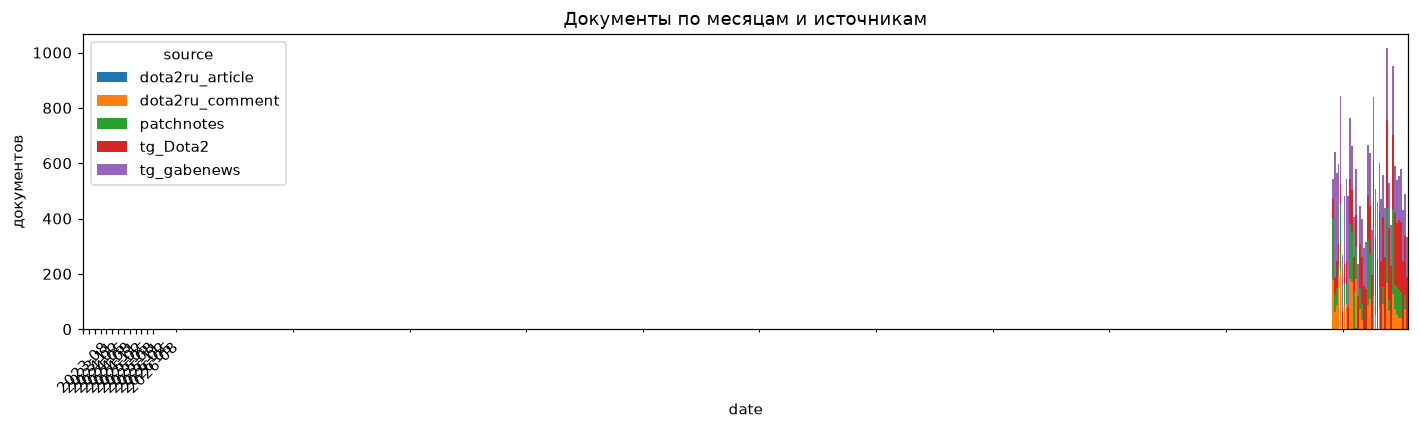

In [3]:
monthly = df.groupby([df["date"].dt.to_period("M"), "source"]).size().unstack(fill_value=0)
ax = monthly.plot(kind="bar", stacked=True, figsize=(13, 4), width=0.9)
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels([str(p) for p in monthly.index[::3]], rotation=45)
ax.set_title("Документы по месяцам и источникам")
ax.set_ylabel("документов")
plt.tight_layout()

## 2. Длины документов

Токены считаются токенизатором **BGE-M3** (XLM-RoBERTa, SentencePiece) — это одна из моделей,
которыми корпус будет индексироваться дальше, так что длины близки к реальным.
Считаем два варианта: сырой текст (как его увидел бы наивный пайплайн, с HTML) и видимый текст без тегов.

In [4]:
from transformers import AutoTokenizer

TOKENIZER = "BAAI/bge-m3"
tok = AutoTokenizer.from_pretrained(TOKENIZER)
len_cache = cache_path("token_lens", "parquet", tokenizer=TOKENIZER)
if len_cache.exists():
    lens = pd.read_parquet(len_cache)
else:
    def count(texts):
        return [len(x) for x in tok(list(texts), add_special_tokens=False)["input_ids"]]
    lens = pd.DataFrame({"doc_id": df["doc_id"], "tok_raw": count(df["text"]), "tok_visible": count(df["visible"])})
    lens.to_parquet(len_cache)
n_before = len(df)
df = df.merge(lens, on="doc_id", how="left", validate="one_to_one")
assert len(df) == n_before and df["tok_raw"].notna().all(), "кэш длин не покрывает корпус"
print("токенов всего: сырых", df["tok_raw"].sum(), "| видимых", df["tok_visible"].sum())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (97207 > 8192). Running this sequence through the model will result in indexing errors


токенов всего: сырых 10600257 | видимых 2096971


In [5]:
def length_stats(col):
    g = df.groupby("source")[col]
    s = g.describe(percentiles=[0.1, 0.5, 0.9])[["count", "mean", "std", "min", "10%", "50%", "90%", "max"]]
    s["<50_%"] = g.apply(lambda x: (x < 50).mean() * 100)
    s[">2000_%"] = g.apply(lambda x: (x > 2000).mean() * 100)
    s.loc["ВСЕГО"] = [*df[col].describe(percentiles=[0.1, 0.5, 0.9])[["count", "mean", "std", "min", "10%", "50%", "90%", "max"]],
                     (df[col] < 50).mean() * 100, (df[col] > 2000).mean() * 100]
    return s.round(1)

print("Видимый текст:")
display(length_stats("tok_visible"))
print("Сырой текст с разметкой:")
display(length_stats("tok_raw"))

Видимый текст:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,10339.3,14138.5,1591.0,2434.0,4145.5,25528.0,54945.0,0.0,97.2
dota2ru_comment,2692.0,30.5,33.6,0.0,6.0,21.0,64.0,502.0,83.9,0.0
patchnotes,3447.0,94.0,130.7,10.0,24.0,54.0,203.4,2226.0,45.8,0.1
tg_Dota2,6964.0,74.5,56.7,0.0,35.0,57.0,135.7,956.0,37.3,0.0
tg_gabenews,7851.0,101.9,77.1,8.0,35.0,80.0,194.0,870.0,26.6,0.0
ВСЕГО,20990.0,99.9,721.3,0.0,24.0,58.0,167.0,54945.0,40.6,0.2


Сырой текст с разметкой:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,51336.7,57152.7,13491.0,15639.5,26752.0,115746.0,233904.0,0.0,100.0
dota2ru_comment,2692.0,74.1,57.0,21.0,35.0,55.0,124.0,801.0,41.5,0.0
patchnotes,3447.0,94.5,132.9,10.0,24.0,54.0,204.0,2226.0,45.6,0.1
tg_Dota2,6964.0,429.0,611.0,33.0,181.0,248.0,767.0,7324.0,0.0,2.7
tg_gabenews,7851.0,667.3,472.3,41.0,296.0,508.0,1218.0,6974.0,0.0,1.7
ВСЕГО,20990.0,505.0,3186.3,10.0,42.0,282.0,928.0,233904.0,12.8,1.7


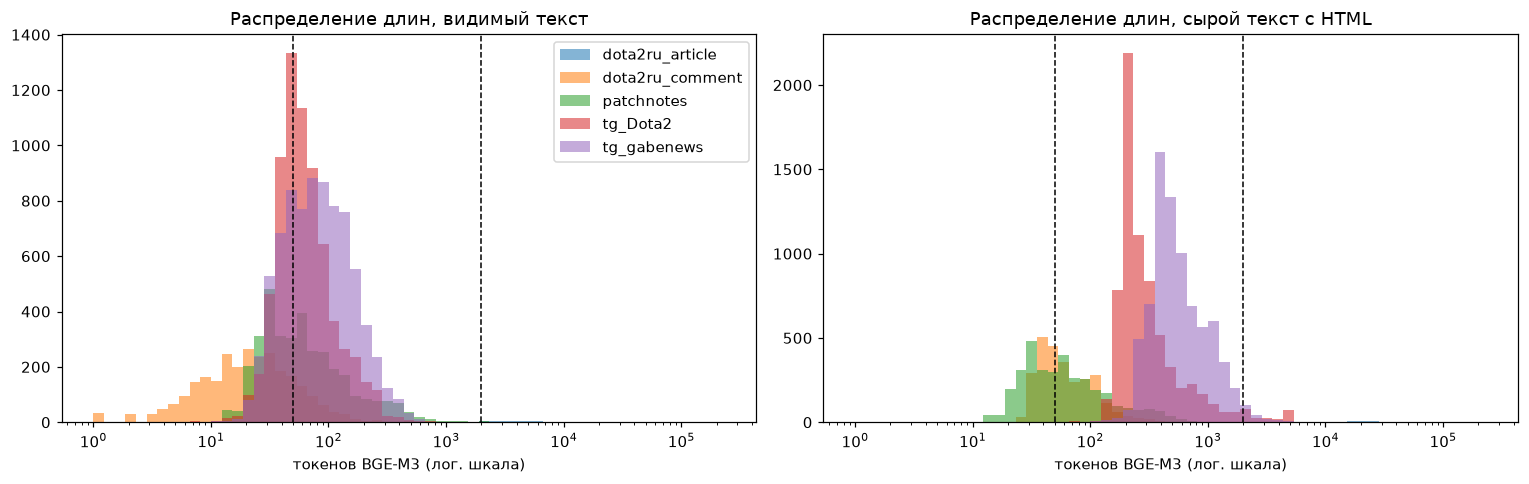

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.logspace(0, np.log10(df["tok_raw"].max() + 1), 60)
for ax, col, title in zip(axes, ["tok_visible", "tok_raw"], ["видимый текст", "сырой текст с HTML"]):
    for src, g in df.groupby("source"):
        ax.hist(g[col].clip(lower=1), bins=bins, alpha=0.55, label=src)
    ax.set_xscale("log")
    ax.axvline(50, color="k", ls="--", lw=1)
    ax.axvline(2000, color="k", ls="--", lw=1)
    ax.set_title(f"Распределение длин, {title}")
    ax.set_xlabel("токенов BGE-M3 (лог. шкала)")
axes[0].legend()
plt.tight_layout()

Примеры выбросов: самые короткие и самые длинные документы.

In [7]:
cols = ["source", "tok_visible", "visible"]
display(df[df["tok_visible"] < 5].sample(8, random_state=1)[cols])
display(df.nlargest(5, "tok_visible")[["source", "tok_visible", "tok_raw", "title"]])

,source,tok_visible,visible
4807,dota2ru_comment,2,Душно
5669,dota2ru_comment,4,Где аспекты?
3953,dota2ru_comment,2,харош
3526,dota2ru_comment,4,Боби мид
5767,dota2ru_comment,0,
4244,dota2ru_comment,2,Джадж
3701,dota2ru_comment,2,манта
4243,dota2ru_comment,2,кого?


,source,tok_visible,tok_raw,title
4359,dota2ru_article,54945,211056,В Dota 2 вышел глобальный патч 7.36. Добавлены две новые механики: врождённые способности и аспекты
5768,dota2ru_article,50064,233904,В Dota 2 вышел патч 7.41 — удалены аспекты
5001,dota2ru_article,49137,186260,В Dota 2 вышел патч 7.38 «Вольные воды»
5536,dota2ru_article,28264,132012,"В Dota 2 вышел патч 7.40 — изменения карты, балансные правки и обновлённый порядок драфта в CM"
5196,dota2ru_article,22792,99480,В Dota 2 вышел патч 7.39 «Весенняя встряска»


## 3. Шум: доля «мусорных» токенов

Доли считаются **в токенах BGE-M3** — тех же единицах, что и длины выше, то есть это доля
входного окна модели. Каждому символу сырого текста присваивается класс, токен получает класс
своего первого символа (по `offset_mapping` токенизатора). Приоритет классов при пересечении:
URL (в том числе в `href`/`src`) > HTML-тег > эмодзи > число > пунктуация > прочий спецсимвол > буквы.

* **Удаляемый шум** — кандидаты на удаление в КТ 2: HTML, URL, эмодзи, прочие спецсимволы
  (`|`, `#`, `@`, `→`, декоративные символы).
* **Не шум** — буквы, числа и обычная пунктуация. Числа показаны отдельно: в патчноутах это суть
  правки («урон увеличен с 75 до 80»), удалять их нельзя.

In [8]:
URL_RE = re.compile(r"https?://[^\s\"'<>]+|www\.[^\s\"'<>]+|t\.me/[^\s\"'<>]+")
CLASSES = ["space", "word", "num", "punct", "special", "emoji", "html", "url"]  # индекс = приоритет
SPAN_RES = [  # от низкого приоритета к высокому — более поздний перезаписывает
    (1, re.compile(r"[^\W\d_]+")),
    (4, re.compile(r"[^\w\s]|_")),
    (3, re.compile(r"[.,!?:;…\-–—«»\"'()\[\]]")),
    (2, re.compile(r"\d+")),
]
NOISE = ["html", "url", "emoji", "special"]


def char_classes(text: str) -> np.ndarray:
    codes = np.zeros(len(text), dtype=np.int8)
    for code, rx in SPAN_RES:
        for m in rx.finditer(text):
            codes[m.start():m.end()] = code
    for e in emoji.emoji_list(text):
        codes[e["match_start"]:e["match_end"]] = 5
    for m in TAG_RE.finditer(text):
        codes[m.start():m.end()] = 6
    for m in URL_RE.finditer(text):
        codes[m.start():m.end()] = 7
    return codes


def token_class_counts(text: str) -> np.ndarray:
    offs = tok(text, add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]
    starts = np.array([s for s, e in offs if e > s], dtype=np.int64)
    if not len(starts):
        return np.zeros(len(CLASSES), dtype=np.int64)
    return np.bincount(char_classes(text)[starts], minlength=len(CLASSES))


noise_cache = cache_path("token_classes", "parquet", tokenizer=TOKENIZER, classes=CLASSES,
                         spans=[r.pattern for _, r in SPAN_RES], url=URL_RE.pattern)
if noise_cache.exists():
    noise = pd.read_parquet(noise_cache)
else:
    noise = pd.DataFrame(np.vstack([token_class_counts(t) for t in df["text"]]), columns=CLASSES)
    noise.insert(0, "doc_id", df["doc_id"].values)
    noise.to_parquet(noise_cache)
assert noise["doc_id"].tolist() == df["doc_id"].tolist(), "кэш классов не совпадает с корпусом"
noise["source"] = df["source"].values

share = noise.groupby("source")[CLASSES[1:]].sum()
share.loc["ВСЕГО"] = share.sum()
share = share.div(share.sum(axis=1), axis=0) * 100
share["удаляемый_шум_%"] = share[NOISE].sum(axis=1)
share.round(1)

,word,num,punct,special,emoji,html,url,удаляемый_шум_%
source,,,,,,,,
dota2ru_article,14.7,1.6,2.5,2.2,0.0,78.6,0.4,81.2
dota2ru_comment,36.4,0.8,4.0,0.2,0.0,57.5,1.0,58.7
patchnotes,71.3,11.4,12.3,4.3,0.0,0.6,0.0,4.9
tg_Dota2,13.6,0.7,1.4,0.4,0.9,80.6,2.4,84.3
tg_gabenews,11.5,0.4,1.4,0.4,1.0,82.6,2.7,86.7
ВСЕГО,15.0,1.0,2.0,0.8,0.7,78.3,2.1,82.0


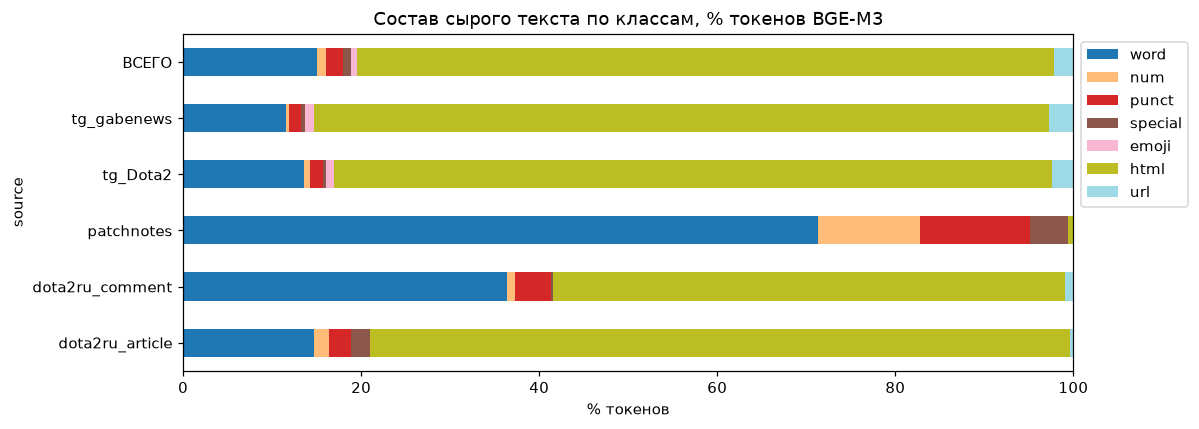

In [9]:
share[CLASSES[1:]].plot(kind="barh", stacked=True, figsize=(11, 4), colormap="tab20")
plt.title("Состав сырого текста по классам, % токенов BGE-M3")
plt.xlabel("% токенов")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()

Дополнительные признаки «грязи» по источникам: доля документов с эмодзи, ссылками, цитатами,
пересылками, медиа без текста, а также рекламные маркеры в Telegram.

In [10]:
# «бонус» сюда не входит: в патчноутах это игровой термин («бонус к урону»)
ADS_RE = re.compile(r"промокод|ставк|казино|букмекер|фрибет|реклама|erid|бездеп", re.I)
flags = pd.DataFrame({
    "source": df["source"],
    "с эмодзи": noise["emoji"].values > 0,
    "со ссылкой": df["text"].str.contains(URL_RE),
    "с цитатой": df["meta"].map(lambda m: bool(m.get("has_quote"))),
    "пересылка": df["meta"].map(lambda m: bool(m.get("forwarded_from"))),
    "медиа": df["meta"].map(lambda m: bool(m.get("has_photo") or m.get("has_video"))),
    "реклама/ставки": df["visible"].str.contains(ADS_RE),
    "латиница>50%": df["visible"].map(lambda t: sum(ch.isascii() and ch.isalpha() for ch in t) > 0.5 * max(1, sum(ch.isalpha() for ch in t))),
})
(flags.groupby("source").mean() * 100).round(1)

,с эмодзи,со ссылкой,с цитатой,пересылка,медиа,реклама/ставки,латиница>50%
source,,,,,,,
dota2ru_article,0.0,100.0,0.0,0.0,0.0,0.0,0.0
dota2ru_comment,0.0,0.8,0.0,0.0,0.0,0.1,0.8
patchnotes,0.0,0.0,0.0,0.0,0.0,0.0,1.8
tg_Dota2,99.6,91.8,0.0,2.6,99.2,0.9,1.0
tg_gabenews,99.8,93.6,0.0,0.3,96.2,1.0,3.9


## 4. Дубликаты и near-duplicates

Только фиксируем, ничего не удаляем (удаление — шаг предобработки КТ 2).
* **Точные** — совпадение видимого текста после приведения к нижнему регистру и схлопывания пробелов.
* **Почти-дубликаты** — пары с Jaccard ≥ 0.8 по множествам словесных 3-грамм. MinHash LSH
  (128 перестановок) используется только для генерации кандидатов — это вероятностный фильтр,
  поэтому для каждой пары-кандидата Jaccard пересчитывается точно и пары ниже порога отбрасываются.
  Документы короче 5 слов не участвуют — у них почти нет шинглов.

In [11]:
norm = df["visible"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
h = norm.map(lambda t: hashlib.md5(t.encode()).hexdigest())
dup_groups = h[h.duplicated(keep=False)].groupby(h).size()
exact = pd.DataFrame({"source": df["source"], "exact_dup": h.duplicated(keep="first")})
print(f"Точные дубликаты: {exact['exact_dup'].sum()} лишних копий ({exact['exact_dup'].mean()*100:.1f}% корпуса), групп {len(dup_groups)}")
display(exact.groupby("source")["exact_dup"].agg(["sum", "mean"]).assign(mean=lambda x: (x["mean"] * 100).round(1)).rename(columns={"sum": "копий", "mean": "%"}))
top = df.loc[h.isin(dup_groups.nlargest(6).index)].groupby(h)["visible"].agg(["size", "first"]).sort_values("size", ascending=False)
top

Точные дубликаты: 463 лишних копий (2.2% корпуса), групп 346


,копий,%
source,,
dota2ru_article,0,0.0
dota2ru_comment,44,1.6
patchnotes,12,0.3
tg_Dota2,255,3.7
tg_gabenews,152,1.9


,size,first
visible,,
331c725db66a295968e9ec5c5b4cea54,22,Данный комментарий был удален.
d41d8cd98f00b204e9800998ecf8427e,20,
687f2a2ef65cff682caf46e04c4819d6,16,🏆 Еженедельный мета-отчет Эти герои показывают себя лучше других на 7.000+ MMR Не забудь сохранить и поделиться с др...
05c93a62c47deec349d1836d3b93b04f,8,🎖 Мета-отчет нового патча После выхода обновления эти персонажи показывают себя лучше всех на высоком рейтинге Сохра...
926ae08934acd05c78b454b420b28eee,8,"🏆 Еженедельный мета-отчет Худшие герои на каждой роли на 7.000+ MMR Скинь другу, пусть не берет этих героев в рейтин..."
51e00500dedd820afba5d8e73a2f2095,5,"😮 В Dota вышел новый патч 7.37d, ниже самое интересное из обновления • Добавили новую сокровищницу Collector Cache 2..."


In [12]:
JACCARD = 0.8
words = norm.str.findall(r"\w+")
shingles = {d: {" ".join(w[j:j + 3]) for j in range(len(w) - 2)} for d, w in zip(df["doc_id"], words) if len(w) >= 5}
mh_cache = cache_path("near_dup_pairs", "json", shingle=3, min_words=5, num_perm=128, threshold=JACCARD)
if mh_cache.exists():
    cand = json.loads(mh_cache.read_text())
else:
    lsh = MinHashLSH(threshold=JACCARD, num_perm=128)
    mhs = {}
    for d, sh in shingles.items():
        m = MinHash(num_perm=128, seed=1)
        m.update_batch([x.encode() for x in sh])
        mhs[d] = m
        lsh.insert(d, m)
    cand = sorted({tuple(sorted((d, o))) for d, m in mhs.items() for o in lsh.query(m) if o != d})
    mh_cache.write_text(json.dumps(cand, ensure_ascii=False))

jac = lambda a, b: len(shingles[a] & shingles[b]) / len(shingles[a] | shingles[b])
hash_by_id = dict(zip(df["doc_id"], h))
cand = [(a, b, jac(a, b)) for a, b in cand if hash_by_id[a] != hash_by_id[b]]  # точные посчитаны выше
pairs = [(a, b, j) for a, b, j in cand if j >= JACCARD]
near_ids = {d for a, b, _ in pairs for d in (a, b)}
print(f"Кандидатов от LSH (не точных): {len(cand)}, из них подтверждено точным Jaccard ≥ {JACCARD}: {len(pairs)} "
      f"(отброшено {len(cand) - len(pairs)}, минимальный Jaccard среди отброшенных: "
      f"{min((j for *_, j in cand if j < JACCARD), default=float('nan')):.3f})")
print(f"Затронуто документов: {len(near_ids)} ({len(near_ids)/len(df)*100:.1f}%)")
src = dict(zip(df["doc_id"], df["source"]))
pair_src = Counter(" ↔ ".join(sorted({src[a], src[b]})) if src[a] != src[b] else src[a] for a, b, _ in pairs)
pd.Series(pair_src, name="пар").sort_values(ascending=False).to_frame()

Кандидатов от LSH (не точных): 202, из них подтверждено точным Jaccard ≥ 0.8: 178 (отброшено 24, минимальный Jaccard среди отброшенных: 0.565)
Затронуто документов: 330 (1.6%)


,пар
tg_Dota2,92
tg_gabenews,83
tg_Dota2 ↔ tg_gabenews,2
patchnotes,1


In [13]:
vis = dict(zip(df["doc_id"], df["visible"]))
rng = np.random.default_rng(0)
for a, b, j in [pairs[i] for i in rng.choice(len(pairs), size=min(4, len(pairs)), replace=False)]:
    print(f"Jaccard {j:.2f}\n[{src[a]}] {vis[a][:200]}\n[{src[b]}] {vis[b][:200]}\n" + "-" * 80)

Jaccard 1.00
[tg_Dota2] 🔥 Арканы с прогнозов можно продать Арканы полученные в награду можно передавать друзьям и продавать на торговой площадке Работает только с Арканами на Vengeful Spirit и Skywrath Mage Кроме того, можно
[tg_Dota2] 🔥 Арканы с прогнозов можно продать Арканы полученные в награду можно передавать друзьям и продавать на торговой площадке Работает только с Арканами на Vengeful Spirit и Skywrath Mage Кроме того, можно
--------------------------------------------------------------------------------
Jaccard 0.98
[tg_Dota2] 🔥 Io — сильнейший герой в Доте? Про-игроки начали активно абузить этого героя и даже Nix не прошел и высказался: По‑моему, это просто имба. С ним нельзя просто так в драку лезть Кто умеет играть Виспо
[tg_Dota2] 🔥 Io — сильнейший герой в Доте? Про-игроки начали активно абузить этого героя и даже Nix не прошел и высказался: По‑моему, это просто имба. С ним нельзя просто так в драку лезть Кто умеет играть Виспо
---------------------------------------------

## 5. Тематические кластеры

Видимый текст (первые 512 токенов) кодируется моделью `intfloat/multilingual-e5-small`
(на GPU, если он есть), затем KMeans. Ключевые слова кластера — TF-IDF по «склеенному» тексту кластера,
где слова, встречающиеся в большинстве кластеров, отсекаются (`max_df`).
Это разведочный анализ: цель — увидеть, из каких тем состоит корпус, а не выбрать модель.

In [14]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

import torch

EMB_MODEL = "intfloat/multilingual-e5-small"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # на CPU тот же результат, но заметно дольше
emb_cache = cache_path("emb", "npy", model=EMB_MODEL, max_seq_length=512, prefix="passage: ")
if emb_cache.exists():
    emb = np.load(emb_cache)
else:
    model = SentenceTransformer(EMB_MODEL, device=DEVICE)
    model.max_seq_length = 512
    emb = model.encode(["passage: " + t for t in df["visible"]], batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    np.save(emb_cache, emb)
assert emb.shape[0] == len(df), "кэш эмбеддингов не совпадает с корпусом"

K = 14
df["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(emb)
STOP = set("""и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот от меня
еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж вам ведь там потом себя
ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтобы без будто чего раз тоже себе под будет ж тогда кто
этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были куда зачем всех никогда можно при
наконец два об другой хоть после над больше тот через эти нас про всего них какая много разве три эту моя впрочем хорошо свою
этой перед иногда лучше чуть том нельзя такой им более всегда конечно всю между это the of to and in is for on""".split())
docs_by_cl = df.groupby("cluster")["visible"].apply(lambda s: " ".join(s.str.lower()))
vec = TfidfVectorizer(max_df=0.5, min_df=2, token_pattern=r"(?u)\b[^\W\d_]{3,}\b", stop_words=list(STOP), max_features=50000)
X = vec.fit_transform(docs_by_cl)
terms = np.array(vec.get_feature_names_out())
clusters = pd.DataFrame({
    "docs": df.groupby("cluster").size(),
    "top_terms": [", ".join(terms[np.argsort(-X[i].toarray()[0])[:10]]) for i in range(K)],
})
clusters = clusters.join((pd.crosstab(df["cluster"], df["source"], normalize="index") * 100).round(0))
clusters.sort_values("docs", ascending=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,docs,top_terms,dota2ru_article,dota2ru_comment,patchnotes,tg_Dota2,tg_gabenews
cluster,,,,,,,
13,2150,"счетом, составе, galaxy, расписание, azure, организация, сыграют, пройдет, сетки, счётом",0.0,0.0,0.0,35.0,65.0
2,2072,"увеличен, перезарядка, длительность, расход, увеличено, уменьшено, изменён, дальность, рецепта, применения",0.0,0.0,99.0,1.0,0.0
6,2002,"берите, используем, понадобится, контрит, провернуть, мастерскую, обнаружил, нажимаем, используйте, lotus",0.0,1.0,0.0,66.0,32.0
5,1983,"говорить, говоря, смотрю, молодой, карьере, турниры, чувак, составе, карьеры, сравнил",0.0,0.0,0.0,35.0,65.0
12,1710,"фигурка, кейкап, косплей, золо, берите, женщина, сереги, работой, кидай, оформил",0.0,0.0,0.0,94.0,6.0
7,1578,"порезали, норм, нерфят, лвле, валв, помойку, вольво, режут, дума, ибо",0.0,99.0,0.0,0.0,0.0
8,1545,"подводим, четвёрки, читаем, расписание, промежуточные, празднует, исполняется, twitch, подошел, дайджеста",0.0,0.0,0.0,2.0,98.0
10,1437,"увеличен, заменено, длительность, перезарядка, увеличивает, врождённая, расход, применения, дальность, улучшается",1.0,1.0,97.0,1.0,0.0
9,1367,"staging, компендиум, server, teaguvnor, увеличен, обновили, декабря, акта, ночное, файлах",0.0,1.0,0.0,38.0,61.0


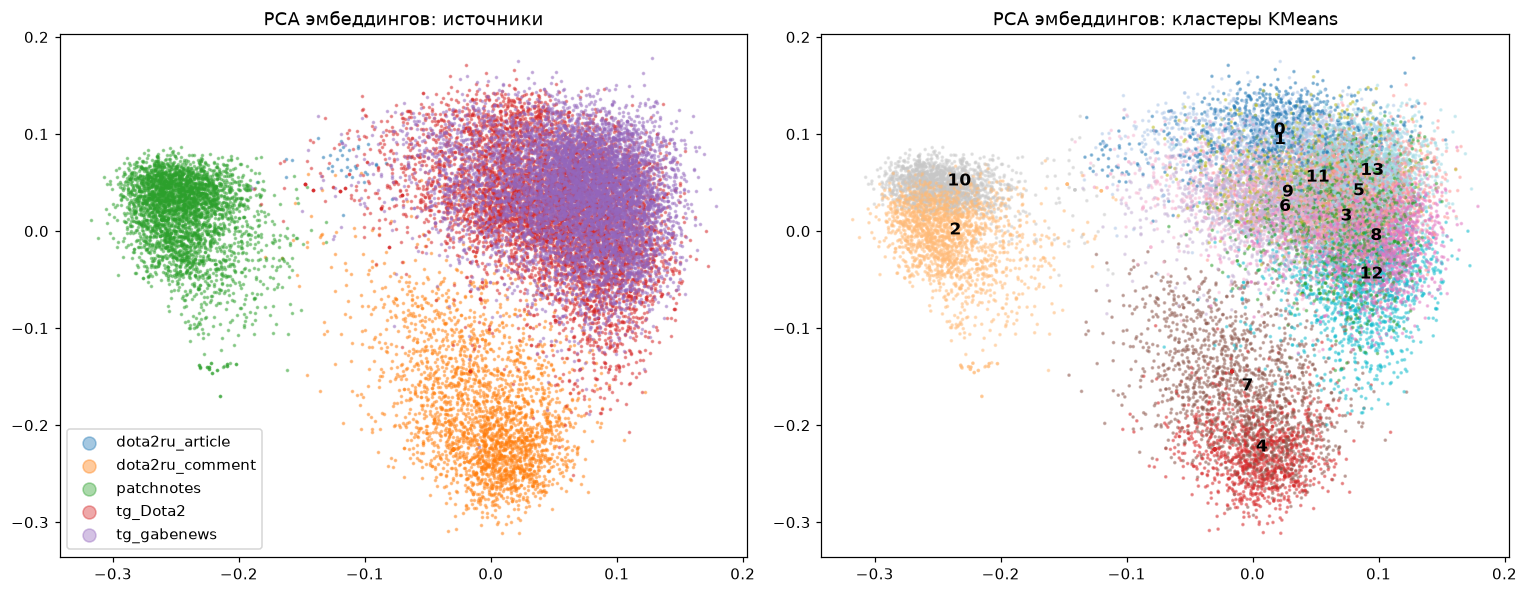

In [15]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(emb)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for src_name, g in df.groupby("source"):
    axes[0].scatter(xy[g.index, 0], xy[g.index, 1], s=2, alpha=0.4, label=src_name)
axes[0].legend(markerscale=6)
axes[0].set_title("PCA эмбеддингов: источники")
axes[1].scatter(xy[:, 0], xy[:, 1], c=df["cluster"], s=2, alpha=0.4, cmap="tab20")
for c in range(K):
    cx, cy = xy[df["cluster"] == c].mean(axis=0)
    axes[1].text(cx, cy, str(c), fontsize=11, weight="bold")
axes[1].set_title("PCA эмбеддингов: кластеры KMeans")
plt.tight_layout()

Примеры документов из каждого кластера:

In [16]:
for c in clusters.sort_values("docs", ascending=False).index:
    s = df[df["cluster"] == c].sample(2, random_state=0)
    print(f"--- кластер {c}: {clusters.loc[c, 'top_terms'][:80]}")
    for _, r in s.iterrows():
        print(f"  [{r['source']}] {r['visible'][:160]}")

--- кластер 13: счетом, составе, galaxy, расписание, azure, организация, сыграют, пройдет, сетки
  [tg_gabenews] 🏆 Этот день настал! Долгожданный Рияд стартует уже сегодня! Но перед этим главные новости вчерашнего дня: 😳 Яторо нашел скрытую имбу патча — вовсю тренирует ее 
  [tg_Dota2] 😲 Саппорты Tundra вдвоем забирают Рошана на 11-й минуте Подъехали заготовочки к главному турниру этого лета: для реализации потребуются Warlock и Shadow Shaman 
--- кластер 2: увеличен, перезарядка, длительность, расход, увеличено, уменьшено, изменён, даль
  [patchnotes] Патч 7.41 — Сатир-мучитель - Shockwave: урон изменён со 160 на 140/160/180/200
  [patchnotes] Патч 7.39 — Rubick Telekinesis: - Перезарядка уменьшена с 24/21/18/15 до 23/20/17/14 секунд Spell Steal: - Некоторые переключаемые способности, которые не расхо
--- кластер 6: берите, используем, понадобится, контрит, провернуть, мастерскую, обнаружил, наж
  [tg_Dota2] 🎁 Новые Immortal-предметы Участвуя в фэнтези и делая прогнозы на TI, можно по

## 6. Сводка цифр для выводов

In [17]:
summary = {
    "документов": len(df),
    "токенов видимого текста (BGE-M3)": int(df["tok_visible"].sum()),
    "токенов сырого текста": int(df["tok_raw"].sum()),
    "медиана длины, видимый": int(df["tok_visible"].median()),
    "доля < 50 токенов, %": round((df["tok_visible"] < 50).mean() * 100, 1),
    "доля > 2000 токенов, %": round((df["tok_visible"] > 2000).mean() * 100, 1),
    "удаляемого шума в сыром тексте, % токенов": round(share.loc["ВСЕГО", "удаляемый_шум_%"], 1),
    "чисел, % токенов": round(share.loc["ВСЕГО", "num"], 1),
    "точных дубликатов, %": round(exact["exact_dup"].mean() * 100, 1),
    "документов в near-dup парах, %": round(len(near_ids) / len(df) * 100, 1),
}
pd.Series(summary).to_frame("значение")

,значение
документов,20990.0
токенов видимого текста (BGE-M3),2096971.0
токенов сырого текста,10600257.0
"медиана длины, видимый",58.0
"доля < 50 токенов, %",40.6
"доля > 2000 токенов, %",0.2
"удаляемого шума в сыром тексте, % токенов",82.0
"чисел, % токенов",1.0
"точных дубликатов, %",2.2
"документов в near-dup парах, %",1.6


## 7. Выводы

**1. Типичный размер документа и разброс.** Распределение резко неоднородное, с тяжёлым хвостом:
медиана — 58 токенов видимого текста, но стандартное отклонение ~720.
* Комментарии dota2.ru — медиана 21 токен, 84% короче 50 токенов (часто это реплика из пары слов: «+1», «Почему?»).
* Посты Telegram — медиана 57–80 токенов, длинных почти нет (максимум < 1000).
* Блоки патчноутов — медиана 54, но 46% короче 50 (одна правка одного предмета) и редкие крупные блоки
  (масштабные патчи 7.36/7.38/7.41 — до 2,2 тыс. токенов на героя).
* Статьи dota2.ru — всего 36 документов (0,2% корпуса), но 18% всех токенов видимого текста: медиана 4,1 тыс.,
  максимум 55 тыс. токенов; 97% длиннее 2000. Это полные пересказы патчноутов.

В итоге 40,6% документов короче 50 токенов, а 0,2% (все — статьи) длиннее 2000.

**2. Основной шум.** Доли — в токенах BGE-M3, то есть в долях входного окна модели.
* **Удаляемый шум — 82% токенов сырого корпуса**, и почти весь он — HTML-разметка (78%):
  `<i class="emoji">`, `<b>`, `<a href>`, `<br>`, обёртки комментариев. Именно поэтому сырой корпус
  в 5 раз длиннее видимого текста (10,6 млн токенов против 2,1 млн). В Telegram и статьях удаляемого шума
  84–87% и 81%, в комментариях — 59%, в патчноутах — 5% (они пришли из JSON почти чистыми).
* Остальной удаляемый шум мал по объёму, но встречается почти везде: ссылки — 2% токенов, но они есть
  в 92–94% постов Telegram (подпись канала, промо-ссылки); эмодзи — 1% токенов, но есть в 99,6% постов
  (рубрики-заголовки); декоративные спецсимволы — 1%.
* Числа — 1% токенов корпуса, но 11% токенов патчноутов, и это не шум, а суть правки
  («урон увеличен с 75 до 80»): при чистке их удалять нельзя. Пунктуация (2%) — тоже не шум.
* Шаблонный текст, который регулярным шумом не ловится: подписи каналов («Gabe News | Dota 2», «@Dota2»),
  рубрики-шаблоны («Еженедельный мета-отчёт»), удалённые и пустые комментарии (только картинка или цитата).
* Дубликаты: 2,2% лишних точных копий (больше всего — шаблонные посты @Dota2 и «Данный комментарий был удалён»).
  Ещё 1,6% документов (178 пар) — почти-дубликаты с подтверждённым Jaccard ≥ 0,8: в основном отредактированные
  и перепощенные посты одного канала. LSH дал 202 кандидата, 24 из них после точной проверки отброшены.
* Реклама ставок оказалась редкой (~1% постов) — каналы отфильтрованы по теме.

**3. Тематические кластеры.** Эмбеддинги разделяют корпус прежде всего по **стилю источника** —
патчноуты, посты Telegram и комментарии почти не смешиваются в одном кластере, — а уже внутри по теме:
* изменения способностей, героев и предметов — патчноуты (три кластера, все на 98–100% из патчноутов);
* турниры, расписания, результаты; карьеры игроков и интервью; розыгрыши и призовые фонды;
* мета и статистика: винрейты, пикрейты, «худшие и лучшие герои на ранге» — регулярные посты-шаблоны;
* советы, билды, механики; косметика, мемы, косплей, хайлайты;
* обновления в процессе: staging-сервер, компендиум, ночные патчи;
* реакции форума — жалобы на нерфы, короткие эмоции и сленг («пач», «порезали», «вольво»).

**4. Проблемы для чанкинга и ретрива.**
* **Один размер чанка не подходит никому:** статьи надо резать, а 40% документов и так короче 50 токенов —
  фиксированный чанк в 512 токенов для них бессмыслен, а короткие комментарии без контекста статьи
  («что с ним») почти не несут информации — понадобятся метаданные (к какому патчу/статье относится).
* **Без удаления HTML** 4/5 embedding-окна занято разметкой, а BM25 индексирует имена классов и атрибутов.
* **SentenceChunker** будет ошибаться на постах Telegram: предложения там разделены эмодзи, а не точками.
* **Шаблонные посты и дубликаты** будут занимать несколько мест в top-k одинаковым текстом.
* **Один факт — несколько источников:** правка есть в патчноуте, в статье, в пересказе Telegram и
  в обсуждении. В gold-наборе нужно указывать все релевантные документы, иначе Recall занизится.
* **Разные формы имён:** в патчноутах (русская локализация Valve) имена героев и предметов английские
  (Pudge, Black King Bar), в постах и комментариях — русские и сленговые (Пудж, бкб).
  BM25 на этом будет проигрывать, dense-модели должны быть мультиязычными.
* **Временная неоднозначность:** одна и та же способность меняется в нескольких патчах 7.34–7.41,
  поэтому вопросы без указания патча неоднозначны, а фильтрация по метаданным (патч, дата) должна помогать.